# 02 — Exploring the panel (EDA)

**What this notebook is for:** before we train any model, we look at the data first. A data scientist does not pick an algorithm and hope — they look, form a hypothesis about what kind of pattern might be in the data, and *then* pick the simplest model that could capture it.

**How we will work:** one small step at a time. Each step is a few cells, then we stop, look at the output together, and decide what to check next. Do not run ahead — the next step depends on what this one shows.

**The data:** `../data/processed/panel_2015-2024.parquet` (from the notebooks folder) — 4,672,823 square-days, 2015–2024, Apr–Oct, with the seven FWI codes and the `fire_next_day` label (1 = a fire started in that square the next day).

---

## Step 1 — Load it and take a first look

The very first thing a data scientist does with a new table is the most boring-sounding and the most important: **does it look like what I think it is?**

That means four checks, and nothing else yet:
1. How many rows and columns? (shape)
2. What are the column names and types? (schema)
3. What do the first few rows actually look like? (head)
4. How many fires vs no-fires? (the target — this is the imbalance we talked about)

No charts, no models, no conclusions yet. Just: *is this the table I think I built?*

### 1.1 — Load the panel

We use **Pandas** here, not Spark. Why? For exploration, Pandas is the right tool: the panel is 272 MB, which fits in memory on your Mac, and Pandas lets us look at small pieces interactively, one cell at a time. Spark is for the heavy work later (training on millions of rows). Exploration is a Pandas job.

`pd.read_parquet(...)` reads the Parquet file into a DataFrame — the same kind of table you have seen before, just bigger.

In [21]:
import pandas as pd

panel = pd.read_parquet("../data/processed/panel_2015-2024.parquet")
print("Loaded.")

Loaded.


### 1.2 — Shape: how many rows and columns?

`panel.shape` gives `(rows, columns)`. We expect (4,672,823, 12) — 4,672,823 square-days, and 12 columns: date, latitude, longitude, the 7 FWI codes, fire_next_day, fire_same_day.

If this number is different, stop — something is wrong with the file, and we find out what before going any further.

In [22]:
print(f"Rows: {panel.shape[0]:,}")
print(f"Columns: {panel.shape[1]}")
print(f"Column names: {list(panel.columns)}")

Rows: 4,672,823
Columns: 12
Column names: ['date', 'latitude', 'longitude', 'FFMC', 'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'DSR', 'fire_next_day', 'fire_same_day']


### 1.3 — Types and missing values: what is each column, and is anything blank?

`panel.dtypes` tells you the type of each column (text, decimal number, whole number). `panel.isna().sum()` counts blank values per column.

We expect: `date` is text, `latitude`/`longitude` are decimals, the seven FWI codes are decimals, and `fire_next_day` / `fire_same_day` are whole numbers (0 or 1). And we expect **0 blanks everywhere** — the panel build said so, but this is us checking it ourselves, in the notebook, with our own eyes.

In [23]:
print(panel.dtypes)
print()
print("Missing (blank) values per column:")
print(panel.isna().sum())

date                 str
latitude         float32
longitude        float64
FFMC             float64
DMC              float64
DC               float64
ISI              float64
BUI              float64
FWI              float64
DSR              float64
fire_next_day      int64
fire_same_day      int64
dtype: object

Missing (blank) values per column:
date             0
latitude         0
longitude        0
FFMC             0
DMC              0
DC               0
ISI              0
BUI              0
FWI              0
DSR              0
fire_next_day    0
fire_same_day    0
dtype: int64


### 1.4 — Head: what do the first 5 rows look like?

`panel.head()` shows the first 5 rows. Read them like a person, not like a machine:
- Are the dates in Apr–Oct 2015 (the start of the panel)?
- Are the latitudes/longitudes inside BC (lat 48–60, lon −139 to −114)?
- Do the FWI values look plausible (small numbers in early April, not 500)?
- Is `fire_next_day` 0 or 1 — never anything else?

If a row looks wrong here, it is usually wrong everywhere, and it is much cheaper to catch it now than after training a model on it.

In [24]:
panel.head()

,date,latitude,longitude,FFMC,DMC,DC,ISI,BUI,FWI,DSR,fire_next_day,fire_same_day
0,2015-04-01,48.50,-124.00,44.891354,0.708520,3.075670,0.162149,0.899190,0.041744,0.000098,0,0
1,2015-04-01,48.50,-123.75,58.751844,1.251842,3.853485,0.678813,1.381610,0.190957,0.001452,0,0
2,2015-04-01,48.50,-123.50,64.281621,1.499947,6.226149,0.842932,1.872269,0.256229,0.002443,0,0
3,2015-04-01,48.75,-124.50,38.099045,0.368030,3.214474,0.042127,0.572262,0.010104,0.000008,0,0
4,2015-04-01,48.75,-124.25,43.018743,0.373374,3.275926,0.098782,0.581155,0.023743,0.000036,0,0


### 1.5 — The target: how many fires vs no-fires?

`panel["fire_next_day"].value_counts()` counts how many rows are 0 and how many are 1. We expect 11,307 ones and 4,661,516 zeros — 0.242% fires.

This is the imbalance, in the notebook, from the real file. Write down what you see before moving on — this number shapes every decision that follows (recall over accuracy, class weights, the whole lot).

In [25]:
counts = panel["fire_next_day"].value_counts()
print(counts)
print()
print(f"Fire rate: {counts[1] / len(panel) * 100:.3f}%")
print(f"That is about 1 fire in every {len(panel) // counts[1]:,} square-days.")

fire_next_day
0    4661516
1      11307
Name: count, dtype: int64

Fire rate: 0.242%
That is about 1 fire in every 413 square-days.


---

## Stop here — Step 1 is done when you can answer these four questions

1. How many rows and columns does the panel have?
2. What are the column types, and are there any blanks?
3. What do the first 5 rows look like — do the dates, places and values make sense?
4. How many fire rows vs no-fire rows, and what is the fire rate?

Run the cells above (top to bottom, one at a time), then tell me what you see — especially if **anything** differs from the numbers I wrote above. The next step (Step 2: how the FWI values are distributed, and whether fires look different from non-fires) depends on this one being clean.

---

## Step 2 — Do fire days look different from non-fire days?

Step 1 confirmed the table is what we thought it was. Now the first real question a data scientist asks: **does the weather actually separate fires from non-fires?**

If the FWI values on fire days look the same as on non-fire days, then the weather codes carry no signal, and no model can learn anything from them. If they look clearly different, then there is something to learn — and the *shape* of that difference tells us which kind of model might work.

We check this in two ways, both using only the FWI column for now (one variable, so we can see clearly):

1. **Summary numbers** — the average, middle value and spread of FWI, separately for fire days and non-fire days. (`groupby` + `describe`.)
2. **Fire rate by FWI band** — split FWI into bands (0–5, 5–10, 10–20, 20–30, 30+), and for each band ask: out of all the square-days in that band, what fraction had a fire the next day? If the fraction climbs steadily as FWI climbs, that is a clean, learnable pattern. If it is flat, FWI alone does not separate the two groups.

One thing to watch for while you read the output: **how big is the difference, not just whether there is one?** With 4.7 million rows, even a tiny difference can look "real" in the numbers. What matters for modelling is whether the difference is big enough that a model could use it to tell the two groups apart.

### 2.1 — Summary numbers: FWI on fire days vs non-fire days

`panel.groupby("fire_next_day")["FWI"].describe()` splits the rows into two groups — label 0 (no fire tomorrow) and label 1 (fire tomorrow) — and for each group prints: how many rows (`count`), the average (`mean`), the spread (`std`), the smallest (`min`), the middle value (`50%`, the median), and the largest (`max`).

Read it like this: if the `mean` and `50%` for group 1 are clearly higher than for group 0, then fire days had drier, more dangerous weather the day before. Also look at the overlap — if the ranges overlap a lot, then FWI alone cannot separate the groups cleanly, and the model will need the other six codes too.

In [26]:
panel.groupby("fire_next_day")["FWI"].describe()

,count,mean,std,min,25%,50%,75%,max
fire_next_day,,,,,,,,
0,4661516.0,6.597347,8.873439,4.008635e-10,0.248416,2.422928,10.324582,80.467240
1,11307.0,15.955089,12.142268,6.864375e-09,5.538112,14.479012,24.216695,71.845013


### 2.1b — The same thing as a picture

A table of numbers is hard to *feel*. A picture of the two distributions is much easier: where does each group pile up, and how much do they overlap?

We draw **two histograms on the same axes** — one for non-fire days (blue), one for fire days (orange). Each bar shows how many square-days fall in that FWI range. Because there are 400× more non-fire days than fire days, we plot **density** (`density=True`) instead of raw counts: each histogram is scaled so its total area is 1, so you are comparing *shapes*, not sizes. Otherwise the fire-day histogram would be invisible next to the non-fire one.

Two things to look for:
- **Where is the peak?** The non-fire peak should be near FWI 0–2; the fire peak should be much further right.
- **How much do they overlap?** The area where both colours show is the region where FWI alone cannot tell the two groups apart.

The vertical dashed lines mark the two **medians** (2.42 for non-fires, 14.48 for fires) — the same numbers from the table in 2.1, now as lines you can see.

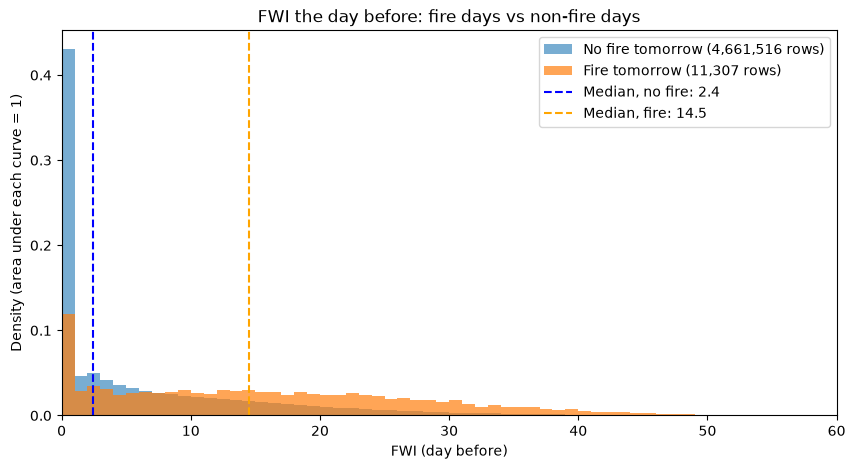

In [27]:
import matplotlib.pyplot as plt

no_fire = panel.loc[panel["fire_next_day"] == 0, "FWI"]
fire = panel.loc[panel["fire_next_day"] == 1, "FWI"]

plt.figure(figsize=(10, 5))
plt.hist(no_fire, bins=60, range=(0, 60), density=True, alpha=0.6,
         label="No fire tomorrow (4,661,516 rows)")
plt.hist(fire, bins=60, range=(0, 60), density=True, alpha=0.7,
         label="Fire tomorrow (11,307 rows)")
plt.axvline(no_fire.median(), color="blue", linestyle="--",
            label=f"Median, no fire: {no_fire.median():.1f}")
plt.axvline(fire.median(), color="orange", linestyle="--",
            label=f"Median, fire: {fire.median():.1f}")
plt.xlim(0, 60)
plt.xlabel("FWI (day before)")
plt.ylabel("Density (area under each curve = 1)")
plt.title("FWI the day before: fire days vs non-fire days")
plt.legend()
plt.show()

**How to read this chart:** the blue hump is piled up on the left (most non-fire days had low FWI), while the orange hump is spread out to the right (fire days had much higher FWI). The two dashed lines — the medians — are far apart, which is the visual version of the table in 2.1. But notice the overlap: there is a big region, roughly FWI 5–25, where both colours are present. In that region, FWI alone cannot tell you whether a fire will happen tomorrow — which is why the model needs the other six codes too.

*Note: the x-axis stops at 60 so the picture is readable. A small number of rows have FWI above 60 (the max is about 80), but they are too few to see at this scale.*

### 2.2 — Fire rate by FWI band

`pd.cut(...)` puts every row into a band based on its FWI value. Then `groupby` counts, for each band: how many square-days were in it, and how many of those had a fire the next day.

The last column, `fire_rate_pct`, is the one to read: it is the percentage of square-days in that band that had a fire tomorrow. Ask yourself: does it climb as FWI climbs? Is there a band where it suddenly jumps — a tipping point? Or is it flat until the very top band?

Note the bands are uneven (0–5, 5–10, 10–20, 20–30, 30+) on purpose: most square-days have low FWI, so the low end needs finer bands, and the high end is rare enough that one wide band (30+) is enough.

In [28]:
bins = [0, 5, 10, 20, 30, 200]
labels = ["0-5", "5-10", "10-20", "20-30", "30+"]
panel["fwi_band"] = pd.cut(panel["FWI"], bins=bins, labels=labels)

band = panel.groupby("fwi_band", observed=True).agg(
    square_days=("fire_next_day", "size"),
    fires=("fire_next_day", "sum"),
)
band["fire_rate_pct"] = band["fires"] / band["square_days"] * 100
band

,square_days,fires,fire_rate_pct
fwi_band,,,
0-5,2828577,2668,0.094323
5-10,638100,1564,0.245103
10-20,762986,3087,0.404595
20-30,311283,2407,0.773251
30+,131877,1581,1.198844


---

## Stop here — Step 2 is done when you can answer these two questions

1. How different is FWI on fire days vs non-fire days — higher average? Higher middle value? How much overlap?
2. Does the fire rate climb as FWI climbs? Is it a steady climb, or is there a sudden jump in one band?

Run the two cells above, then tell me what you see. The next step (Step 3: do the other six codes add anything, and are they just repeating FWI?) depends on what this one shows.

---

## Step 3 — Do the other six codes add anything, or do they just repeat FWI?

Step 2 showed that FWI alone separates fires from non-fires — but not cleanly. Now the next question: **are the other six codes (FFMC, DMC, DC, ISI, BUI, DSR) telling us something new, or are they just saying the same thing as FWI in different words?**

Remember the chain from the teaching session: FWI is *calculated from* ISI and BUI, DSR is *calculated from* FWI. So we already suspect some of them move together almost perfectly. This step checks that suspicion with numbers.

We do it in two ways:

1. **Correlation matrix** — for every pair of codes, a number from −1 to +1 saying how strongly they move together. +1 means "when one goes up, the other always goes up by the same amount"; 0 means "no relationship"; −1 means "when one goes up, the other goes down". Anything above about 0.9 is basically the same signal twice.
2. **Fire vs non-fire averages for all seven codes** — the same `groupby` + `mean` idea as in 2.1, but for all seven codes at once, so you can see at a glance which codes differ most between fire days and non-fire days.

What to look for: if two codes have a correlation near 1.0, the model does not learn twice as much from having both — and for logistic regression, that near-duplicate can make the results unstable. If a code barely differs between fire and non-fire days, it may add little on its own (though it could still matter *in combination* with others — that is what the models will test).

### 3.1 — Correlation matrix: which codes move together?

`panel[features].corr()` computes the correlation of every code with every other code. The result is a 7×7 table. Read it like this: pick a row and a column — the number where they meet is how strongly those two codes move together. The diagonal is always 1.0 (a code with itself).

Look for pairs above 0.9 first — those are near-duplicates. Then look for pairs that are surprisingly low — those are the codes carrying *different* information.

In [29]:
features = ["FFMC", "DMC", "DC", "ISI", "BUI", "FWI", "DSR"]
panel[features].corr().round(2)

,FFMC,DMC,DC,ISI,BUI,FWI,DSR
FFMC,1.00,0.50,0.32,0.68,0.52,0.63,0.46
DMC,0.50,1.00,0.54,0.58,0.98,0.79,0.75
DC,0.32,0.54,1.00,0.26,0.66,0.42,0.36
ISI,0.68,0.58,0.26,1.00,0.56,0.93,0.85
BUI,0.52,0.98,0.66,0.56,1.00,0.78,0.72
FWI,0.63,0.79,0.42,0.93,0.78,1.00,0.94
DSR,0.46,0.75,0.36,0.85,0.72,0.94,1.00


### 3.1b — The same correlation matrix as a heatmap

A 7×7 table of numbers is hard to scan. A heatmap colours each cell by its value, so the strong pairs jump out at you.

**The colour scale:** green = 0 (no relationship), red = 1 (perfectly together), with shades in between. The diagonal is always red (1.00 — a code with itself). Look for the other red cells first — those are the near-duplicates — and the greenest cells — those are the codes carrying different information.

*The numbers are still printed inside each cell, so nothing from the table above is lost — this is the same data, shown as colour.*

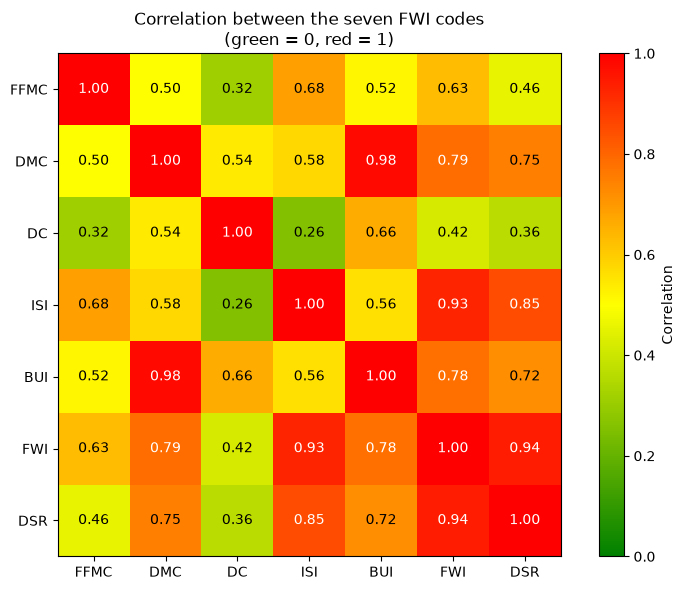

In [30]:
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

corr = panel[features].corr()

# Green (0) -> yellow -> red (1). Red means "moves together perfectly".
cmap = LinearSegmentedColormap.from_list("green_to_red", ["green", "yellow", "red"])

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr.values, cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(features)))
ax.set_yticks(range(len(features)))
ax.set_xticklabels(features)
ax.set_yticklabels(features)
ax.set_title("Correlation between the seven FWI codes\n(green = 0, red = 1)")
for i in range(len(features)):
    for j in range(len(features)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center",
                fontsize=10, color="white" if corr.values[i, j] > 0.75 else "black")
fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

### 3.2 — Average of each code on fire days vs non-fire days

`panel.groupby("fire_next_day")[features].mean()` gives, for each code, its average on non-fire days (row 0) and on fire days (row 1). The last line adds a third row: the **ratio** — how many times higher the fire-day average is than the non-fire-day average.

A ratio near 1.0 means the code barely differs between the two groups. A ratio of 2 or 3 means fire days had two or three times as much of it. The codes with the biggest ratios are the ones that separate the groups most strongly *on their own* — but remember, a code with a small ratio could still help the model when combined with others.

In [31]:
means = panel.groupby("fire_next_day")[features].mean()
means.loc["ratio (fire / no fire)"] = means.loc[1] / means.loc[0]
means.round(2)

,FFMC,DMC,DC,ISI,BUI,FWI,DSR
fire_next_day,,,,,,,
0,69.14,20.57,208.79,3.02,29.84,6.60,1.64
1,84.45,49.51,279.22,5.76,64.29,15.96,5.10
ratio (fire / no fire),1.22,2.41,1.34,1.91,2.15,2.42,3.11


### 3.2b — The same ratios as a bar chart

The table in 3.2 has a problem as a picture: the seven codes live on completely different scales (FFMC goes up to ~100, DC goes into the hundreds, DSR is usually below 10). A bar chart of the raw averages would be unreadable — DC would tower over everything else.

So instead we chart the **ratio** — how many times higher the fire-day average is than the non-fire-day average. Every code is now on the same scale, and the chart answers the question directly: *which codes differ most between fire days and non-fire days?*

A bar reaching to 2 means "twice as high on fire days". A bar near 1 means "barely different". The dashed line at 1 is the "no difference" line — any bar that barely passes it is a code that, on its own, does not separate the two groups.

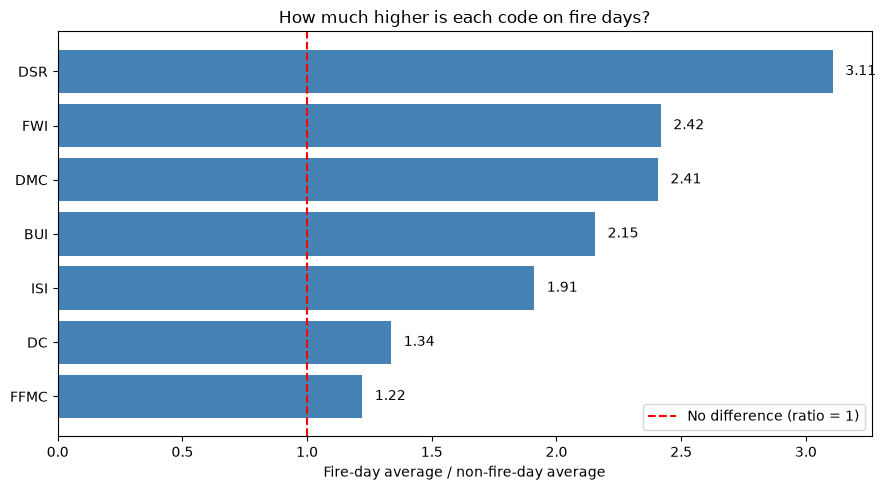

In [32]:
ratio = means.loc[1] / means.loc[0]
ratio = ratio.sort_values()

plt.figure(figsize=(9, 5))
plt.barh(ratio.index, ratio.values, color="steelblue")
plt.axvline(1, color="red", linestyle="--", label="No difference (ratio = 1)")
plt.xlabel("Fire-day average / non-fire-day average")
plt.title("How much higher is each code on fire days?")
plt.legend()
for i, v in enumerate(ratio.values):
    plt.text(v + 0.05, i, f"{v:.2f}", va="center")
plt.tight_layout()
plt.show()

---

## Stop here — Step 3 is done when you can answer these two questions

1. Which pairs of codes are near-duplicates (correlation above ~0.9)? Which pairs are surprisingly unrelated?
2. Which codes differ most between fire days and non-fire days (biggest ratio), and which barely differ at all?

Run the two cells above, then tell me what you see. The next step (Step 4: does the pattern change by year and by region?) depends on what this one shows.

---

## Step 4 — Does the pattern change by year and by region?

Steps 2 and 3 treated the whole panel as one big pile: all years, all of BC. Now a data scientist asks: **is that fair?** Does a fire in the dry interior behave the same as a fire on the wet coast, at the same FWI? Was 2023 (a record fire year) like 2020 (a quiet year)?

If the pattern is the same everywhere and every year, then one global model is fine. If it is different in the north, or in 2023, then a single model might be the wrong choice — or at least, the report needs to show results broken down by region and by year (which is already in the plan).

We check this in two ways:

1. **By year** — for each year 2015–2024: how many square-days, how many fires, and what was the fire rate? Was the fire rate much higher in some years? Did the average FWI also go up in those years (weather-driven), or did fires rise even when FWI did not (something else going on)?
2. **By region** — BC split into four simple regions by latitude and longitude: north (lat ≥ 55) vs south (lat < 55), and coastal (lon < −125) vs interior (lon ≥ −125). For each region: how many square-days, how many fires, what was the fire rate, and what was the average FWI? This is a rough split — not the official fire-centre boundaries — but it is enough to see whether the pattern changes across the province.

What to look for: a year or a region where the fire rate is very different from the overall 0.242%, or where the average FWI does *not* explain the fire rate. Those are the places where a single global model might struggle.

### 4.1 — By year

`panel["date"].str[:4]` takes the first four characters of the date text ("2015-08-18" → "2015") — that is the year. Then we group by year, exactly as in 2.2: how many square-days, how many fires, and the fire rate. The last column is the average FWI that year, so you can compare "was it a dry year?" with "was it a fiery year?" side by side.

In [33]:
panel["year"] = panel["date"].str[:4]

by_year = panel.groupby("year").agg(
    square_days=("fire_next_day", "size"),
    fires=("fire_next_day", "sum"),
    mean_fwi=("FWI", "mean"),
)
by_year["fire_rate_pct"] = by_year["fires"] / by_year["square_days"] * 100
by_year.round(3)

,square_days,fires,mean_fwi,fire_rate_pct
year,,,,
2015,494876,1331,5.900,0.269
2016,479585,822,4.978,0.171
2017,444318,953,8.608,0.214
2018,427990,1462,7.762,0.342
2019,468207,638,4.812,0.136
2020,455816,462,4.238,0.101
2021,461975,1249,7.412,0.270
2022,457651,1336,7.925,0.292
2023,494049,1793,7.997,0.363


### 4.1b — The same thing as a picture

Two bars per year would be hard to read, so this chart shows just the **fire rate by year** — one bar per year, 2015 to 2024. Look for: which years stand out as much higher or lower than the others? Does the pattern match what you know about BC fire seasons (for example, 2017, 2018, 2021 and 2023 were big fire years)?

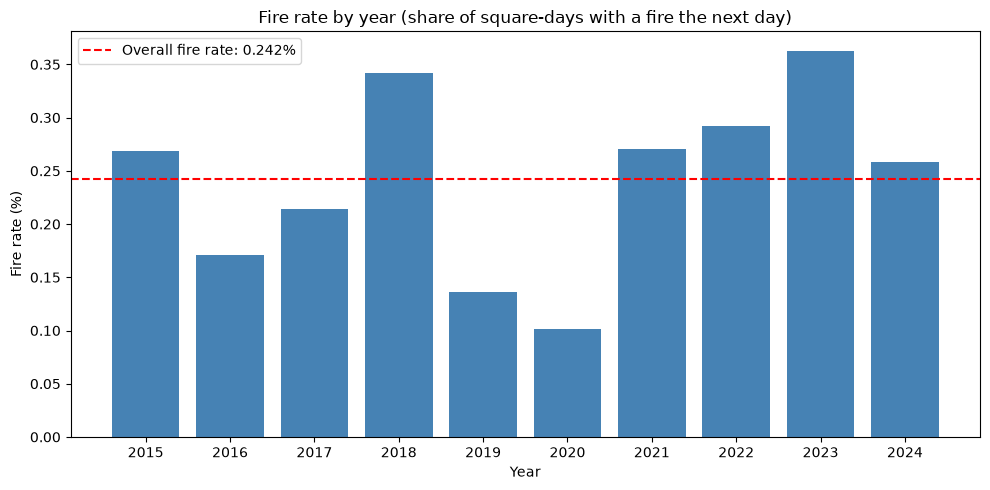

In [34]:
plt.figure(figsize=(10, 5))
plt.bar(by_year.index, by_year["fire_rate_pct"], color="steelblue")
plt.axhline(0.242, color="red", linestyle="--", label="Overall fire rate: 0.242%")
plt.ylabel("Fire rate (%)")
plt.xlabel("Year")
plt.title("Fire rate by year (share of square-days with a fire the next day)")
plt.legend()
plt.tight_layout()
plt.show()

### 4.2 — By region (north/south × coastal/interior)

We make two new columns from latitude and longitude:
- `north_south`: "North" if latitude ≥ 55, otherwise "South". (55°N roughly splits BC in half — Prince George is just below it.)
- `coastal_interior`: "Coastal" if longitude < −125 (the coast mountains and the coast itself), otherwise "Interior".

Combining them gives four regions: North-Coastal, North-Interior, South-Coastal, South-Interior. For each one we count square-days, fires, fire rate, and average FWI — the same as by year, but across space instead of time.

This is a rough split, not the official BC Wildfire fire-centre boundaries. It is good enough to answer "does the pattern change across the province?" — and if it does, the report can use the proper fire-centre boundaries for the final breakdown.

In [35]:
import numpy as np

panel["north_south"] = np.where(panel["latitude"] >= 55, "North", "South")
panel["coastal_interior"] = np.where(panel["longitude"] < -125, "Coastal", "Interior")
panel["region"] = panel["north_south"] + "-" + panel["coastal_interior"]

by_region = panel.groupby("region").agg(
    square_days=("fire_next_day", "size"),
    fires=("fire_next_day", "sum"),
    mean_fwi=("FWI", "mean"),
)
by_region["fire_rate_pct"] = by_region["fires"] / by_region["square_days"] * 100
by_region.round(3)

,square_days,fires,mean_fwi,fire_rate_pct
region,,,,
North-Coastal,844906,520,2.884,0.062
North-Interior,1614910,1320,9.027,0.082
South-Coastal,545520,934,2.867,0.171
South-Interior,1667487,8533,7.410,0.512


### 4.2b — The same thing as a picture

A bar chart of the fire rate by region, with the overall 0.242% as a red dashed line for comparison. Which regions are above the line, and which are below it? And does the average FWI in each region (from the table above) explain it — or is there a region with a high fire rate despite a low average FWI, or vice versa?

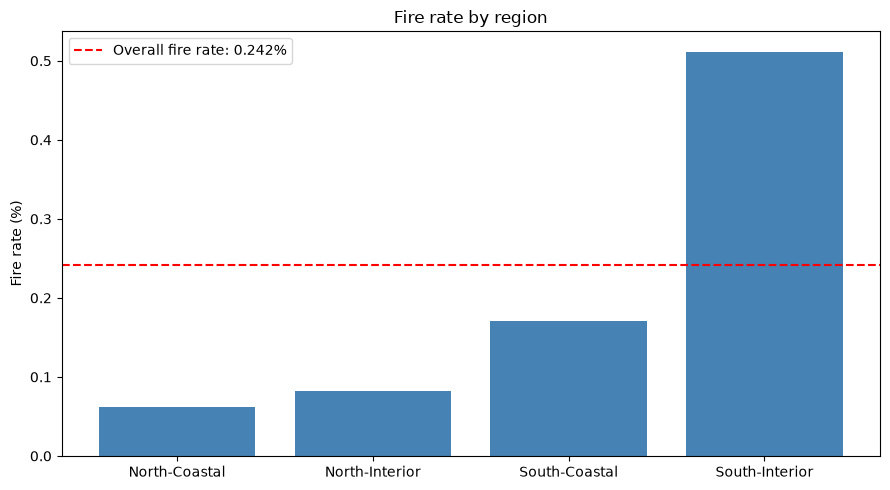

In [36]:
plt.figure(figsize=(9, 5))
plt.bar(by_region.index, by_region["fire_rate_pct"], color="steelblue")
plt.axhline(0.242, color="red", linestyle="--", label="Overall fire rate: 0.242%")
plt.ylabel("Fire rate (%)")
plt.title("Fire rate by region")
plt.legend()
plt.tight_layout()
plt.show()

---

## Stop here — Step 4 is done when you can answer these two questions

1. Which years had a much higher or lower fire rate than the overall 0.242%? Did the average FWI move with it?
2. Which regions had a much higher or lower fire rate than the overall 0.242%? Does their average FWI explain it, or is something else going on?

Run the four cells above, then tell me what you see. After this, the exploration is essentially done, and we will summarise what we learned — and what it means for which model to try first in Step 3 (modelling).